In [ ]:
import pandas as pd

def get_averages_df(data):
    results = data.get("results", {})
    run_scores = defaultdict(list)

    for task, methods in results.items():
        for method, aggregations in methods.items():
            for agg, steerings in aggregations.items():
                for sm, scales in steerings.items():
                    for scale, metrics in scales.items():
                        if "top1" in metrics:
                            run_key = (method, agg, sm, scale)
                            run_scores[run_key].append(metrics["top1"])
    
    rows = []
    for key in sorted(run_scores.keys()):
        method, agg, sm, scale = key
        scores = run_scores[key]
        rows.append({
            "Method": method,
            "Aggregation": agg,
            "Steering": sm,
            "Scale": scale,
            "Avg Top-1": sum(scores) / len(scores) if scores else 0,
            "Task Count": len(scores)
        })
        
    return pd.DataFrame(rows)

df = get_averages_df(eval_data)
display(df)

,Method,Aggregation,Steering,Scale,Avg Top-1,Task Count
0,attn_diff,global,dist,1.0,0.740247,41
1,attn_diff,global,fv,1.0,0.715706,41
2,attn_diff,per_task,dist,1.0,0.651227,41
3,attn_diff,per_task,fv,1.0,0.612860,41
4,cie,global,dist,1.0,0.710893,41
5,cie,global,fv,1.0,0.573317,41
6,cie,per_task,dist,1.0,0.810891,41
7,cie,per_task,fv,1.0,0.684765,41
8,frame_cie,global,dist,1.0,0.731257,41
9,frame_cie,global,fv,1.0,0.684667,41


In [ ]:
def compute_intersections(data, storage_root, prompt_length):
    short_model_name = data.get("model", "Llama-3.2-3B-Instruct")
    prompt_type = data.get("prompt_type", "instruction")
    topk = data.get("topk_heads", 20)
    
    methods = ["cie", "shapley", "lrp"]
    global_heads = {}

    print(f"Recomputing global heads (Top-{topk}) for intersection analysis...")
    for method in methods:
        scores_list = []
        for task in TASKS:
            try:
                save_dir = utils.result_dir(storage_root, short_model_name, task, prompt_length)
                scores_path = Path(save_dir) / f"{task}_{prompt_type}_{method}_head_scores.pt"
                
                if scores_path.exists():
                    s = torch.load(scores_path, map_location="cpu")
                    while s.dim() > 2:
                        s = s.mean(dim=0)
                    scores_list.append(s)
            except Exception:
                continue

        if scores_list:
            avg_score = torch.stack(scores_list).mean(dim=0)
            n_heads = avg_score.shape[1]
            idx = torch.topk(avg_score.flatten(), k=topk).indices
            global_heads[method] = set((int(i) // n_heads, int(i) % n_heads) for i in idx)
        else:
            global_heads[method] = set()

    # --- Compute Intersections ---
    shapley_heads = global_heads.get("shapley", set())
    lrp_heads = global_heads.get("lrp", set())
    cie_heads = global_heads.get("cie", set())

    shapley_lrp = shapley_heads.intersection(lrp_heads)
    shapley_cie = shapley_heads.intersection(cie_heads)

    print("\n=== Global Head Intersections ===")
    print(f"Shapley & LRP Overlap ({len(shapley_lrp)} / {topk} heads):")
    print(sorted(list(shapley_lrp)) if shapley_lrp else "None")
    
    print(f"\nShapley & CIE Overlap ({len(shapley_cie)} / {topk} heads):")
    print(sorted(list(shapley_cie)) if shapley_cie else "None")
    print("=================================")

compute_intersections(eval_data, STORAGE_ROOT, PROMPT_LENGTH)

Recomputing global heads (Top-20) for intersection analysis...

=== Global Head Intersections ===
Shapley & LRP Overlap (0 / 20 heads):
None

Shapley & CIE Overlap (0 / 20 heads):
None


In [ ]:
import os
import json
import torch
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr, kendalltau
from collections import defaultdict
from pathlib import Path

# Ensure your notebook is in the same directory as 'utils.py'
try:
    import utils
except ImportError:
    print("Warning: Could not import 'utils'. Ensure you run this in the same directory as your project.")

# --- Configuration ---
SUMMARY_FILE = "results/Llama-3.2-3B-Instruct_eval_all_20260722_150641.json"  # <-- UPDATE THIS PATH
STORAGE_ROOT = os.environ.get("FV_STORAGE_ROOT", "storage")
PROMPT_LENGTH = "short"

TASKS = [
    "antonym", "capitalize", "capitalize_first_letter", "capitalize_last_letter",
    "country-capital", "country-currency", "english-french", "english-german", "english-spanish",
    "landmark-country", "national_parks",
    "next_item", "park-country", "present-past", "prev_item",
    "product-company", "singular-plural", "synonym", "word_length",
    "alphabetically_last_3", "animal_v_object_3", "animal_v_object_5",
    "choose_first_of_3", "choose_first_of_5", "choose_last_of_3", "choose_last_of_5",
    "choose_middle_of_3", "choose_middle_of_5", "color_v_animal_3", "color_v_animal_5",
    "concept_v_object_3", "concept_v_object_5", "conll2003_location", "conll2003_organization", 
    "conll2003_person", "fruit_v_animal_3", "fruit_v_animal_5",
    "object_v_concept_3", "object_v_concept_5", "verb_v_adjective_3", "verb_v_adjective_5",
]

# Load summary JSON
with open(SUMMARY_FILE, 'r') as f:
    eval_data = json.load(f)

.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


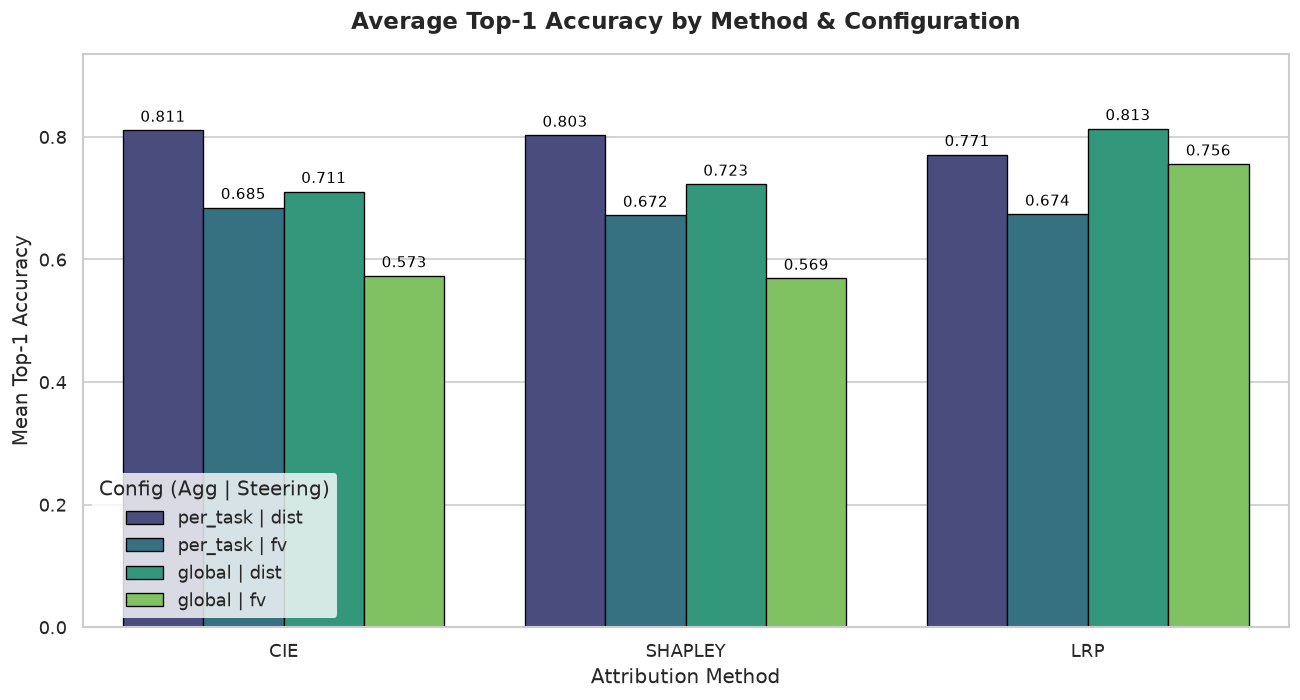

In [ ]:
def plot_averages(data):
    results = data.get("results", {})
    run_scores = defaultdict(list)

    # Extract scores
    for task, methods in results.items():
        for method, aggregations in methods.items():
            for agg, steerings in aggregations.items():
                for sm, scales in steerings.items():
                    for scale, metrics in scales.items():
                        if "top1" in metrics:
                            run_key = (method, agg, sm, scale)
                            run_scores[run_key].append(metrics["top1"])

    rows = []
    for key, scores in run_scores.items():
        method, agg, sm, scale = key
        rows.append({
            "Method": method.upper(),
            "Aggregation": agg,
            "Steering": sm,
            "Scale": float(scale),
            "Avg Top-1": sum(scores) / len(scores) if scores else 0,
            "Task Count": len(scores),
            "Config": f"{agg} | {sm}"
        })
        
    df = pd.DataFrame(rows)

    # --- Plotting ---
    plt.figure(figsize=(11, 6), dpi=120)
    sns.set_theme(style="whitegrid")
    
    ax = sns.barplot(
        data=df,
        x="Method",
        y="Avg Top-1",
        hue="Config",
        palette="viridis",
        edgecolor="black",
        linewidth=0.8
    )

    # Add data labels on top of bars
    for p in ax.patches:
        height = p.get_height()
        if height > 0:
            ax.annotate(f'{height:.3f}',
                        (p.get_x() + p.get_width() / 2., height),
                        ha='center', va='bottom',
                        fontsize=9, color='black',
                        xytext=(0, 3), textcoords='offset points')

    plt.title("Average Top-1 Accuracy by Method & Configuration", fontsize=14, fontweight='bold', pad=15)
    plt.ylabel("Mean Top-1 Accuracy", fontsize=12)
    plt.xlabel("Attribution Method", fontsize=12)
    plt.ylim(0, max(df["Avg Top-1"]) * 1.15)  # Leave room for labels
    plt.legend(title="Config (Agg | Steering)", frameon=True, facecolor='white', edgecolor='none')
    plt.tight_layout()
    plt.show()

    return df

df_averages = plot_averages(eval_data)

In [ ]:
def compute_rank_aware_intersections(data, storage_root, prompt_length):
    short_model_name = data.get("model", "Llama-3.2-3B-Instruct")
    prompt_type = data.get("prompt_type", "instruction")
    topk = data.get("topk_heads", 20)
    
    methods = ["cie", "shapley", "lrp"]
    global_scores = {}

    # 1. Load and aggregate raw head scores across all tasks
    for method in methods:
        scores_list = []
        for task in TASKS:
            try:
                save_dir = utils.result_dir(storage_root, short_model_name, task, prompt_length)
                scores_path = Path(save_dir) / f"{task}_{prompt_type}_{method}_head_scores.pt"
                
                if scores_path.exists():
                    s = torch.load(scores_path, map_location="cpu")
                    while s.dim() > 2:
                        s = s.mean(dim=0)
                    scores_list.append(s)
            except Exception:
                continue

        if scores_list:
            global_scores[method] = torch.stack(scores_list).mean(dim=0)

    if not global_scores:
        print("No head scores could be loaded.")
        return

    # 2. Compute 1-based ranks for every head across the model (1 = Highest Score)
    ranks_dict = {}
    topk_heads_dict = {}
    
    for method, score_tensor in global_scores.items():
        flat_scores = score_tensor.flatten().numpy()
        # Get 1-based ranks (descending order)
        ranks = len(flat_scores) - np.argsort(np.argsort(flat_scores))
        ranks_dict[method] = ranks.reshape(score_tensor.shape)
        
        # Extract Top-K heads
        n_heads = score_tensor.shape[1]
        topk_idx = torch.topk(score_tensor.flatten(), k=topk).indices
        topk_heads_dict[method] = [(int(i) // n_heads, int(i) % n_heads) for i in topk_idx]

    # Helper function to generate comparative DataFrame for overlapping heads
    def get_overlap_df(m1, m2):
        top_m1 = set(topk_heads_dict[m1])
        top_m2 = set(topk_heads_dict[m2])
        overlap = top_m1.intersection(top_m2)
        
        rows = []
        for (l, h) in overlap:
            r1 = int(ranks_dict[m1][l, h])
            r2 = int(ranks_dict[m2][l, h])
            rows.append({
                "Head (L, H)": f"({l}, {h})",
                f"{m1.upper()} Rank": r1,
                f"{m2.upper()} Rank": r2,
                "Rank Delta": abs(r1 - r2)
            })
            
        df = pd.DataFrame(rows)
        if not df.empty:
            df = df.sort_values(by=f"{m1.upper()} Rank").reset_index(drop=True)
        return df

    # 3. Print Rank Comparisons
    print(f"============================================================")
    print(f"             RANK-AWARE GLOBAL HEAD INTERSECTION            ")
    print(f"============================================================\n")

    for pair_a, pair_b in [("shapley", "lrp"), ("shapley", "cie")]:
        df_overlap = get_overlap_df(pair_a, pair_b)
        overlap_count = len(df_overlap)
        
        # Calculate full-model Spearman & Kendall correlation
        flat_a = global_scores[pair_a].flatten().numpy()
        flat_b = global_scores[pair_b].flatten().numpy()
        rho, _ = spearmanr(flat_a, flat_b)
        tau, _ = kendalltau(flat_a, flat_b)

        print(f"--- {pair_a.upper()} vs {pair_b.upper()} ---")
        print(f"Top-{topk} Overlap Count: {overlap_count} / {topk} heads")
        print(f"Full-Model Spearman Correlation (rho): {rho:.4f}")
        print(f"Full-Model Kendall Rank Correlation (tau): {tau:.4f}\n")
        
        if not df_overlap.empty:
            display(df_overlap)
        else:
            print("No overlapping heads in Top-K.\n")
        print("-" * 60 + "\n")

compute_rank_aware_intersections(eval_data, STORAGE_ROOT, PROMPT_LENGTH)

             RANK-AWARE GLOBAL HEAD INTERSECTION            

--- SHAPLEY vs LRP ---
Top-20 Overlap Count: 9 / 20 heads
Full-Model Spearman Correlation (rho): 0.2277
Full-Model Kendall Rank Correlation (tau): 0.1516



,"Head (L, H)",SHAPLEY Rank,LRP Rank,Rank Delta
0,"(14, 16)",1,1,0
1,"(12, 6)",2,4,2
2,"(12, 16)",4,11,7
3,"(12, 3)",5,7,2
4,"(13, 11)",6,3,3
5,"(12, 17)",9,17,8
6,"(14, 20)",13,5,8
7,"(13, 18)",17,19,2
8,"(13, 2)",18,18,0


------------------------------------------------------------

--- SHAPLEY vs CIE ---
Top-20 Overlap Count: 18 / 20 heads
Full-Model Spearman Correlation (rho): 0.6790
Full-Model Kendall Rank Correlation (tau): 0.5163



,"Head (L, H)",SHAPLEY Rank,CIE Rank,Rank Delta
0,"(14, 16)",1,1,0
1,"(12, 6)",2,2,0
2,"(15, 4)",3,3,0
3,"(12, 16)",4,4,0
4,"(12, 3)",5,7,2
5,"(13, 11)",6,6,0
6,"(13, 17)",7,5,2
7,"(19, 7)",8,8,0
8,"(12, 17)",9,9,0
9,"(27, 11)",10,12,2


------------------------------------------------------------



In [ ]:
def compute_rank_aware_intersections(data, storage_root, prompt_length):
    short_model_name = data.get("model", "Llama-3.2-3B-Instruct")
    prompt_type = data.get("prompt_type", "instruction")
    topk = data.get("topk_heads", 20)
    
    methods = ["cie", "shapley", "lrp"]
    global_scores = {}

    # 1. Load and aggregate raw head scores across all tasks
    for method in methods:
        scores_list = []
        for task in TASKS:
            try:
                save_dir = utils.result_dir(storage_root, short_model_name, task, prompt_length)
                scores_path = Path(save_dir) / f"{task}_{prompt_type}_{method}_head_scores.pt"
                
                if scores_path.exists():
                    s = torch.load(scores_path, map_location="cpu")
                    while s.dim() > 2:
                        s = s.mean(dim=0)
                    scores_list.append(s)
            except Exception:
                continue

        if scores_list:
            global_scores[method] = torch.stack(scores_list).mean(dim=0)

    if not global_scores:
        print("No head scores could be loaded.")
        return

    # 2. Compute 1-based ranks for every head across the model (1 = Highest Score)
    ranks_dict = {}
    topk_heads_dict = {}
    
    for method, score_tensor in global_scores.items():
        flat_scores = score_tensor.flatten().numpy()
        # Get 1-based ranks (descending order)
        ranks = len(flat_scores) - np.argsort(np.argsort(flat_scores))
        ranks_dict[method] = ranks.reshape(score_tensor.shape)
        
        # Extract Top-K heads
        n_heads = score_tensor.shape[1]
        topk_idx = torch.topk(score_tensor.flatten(), k=topk).indices
        topk_heads_dict[method] = [(int(i) // n_heads, int(i) % n_heads) for i in topk_idx]

    # Helper 1: DataFrame for overlapping heads
    def get_overlap_df(m1, m2):
        top_m1 = set(topk_heads_dict[m1])
        top_m2 = set(topk_heads_dict[m2])
        overlap = top_m1.intersection(top_m2)
        
        rows = []
        for (l, h) in overlap:
            r1 = int(ranks_dict[m1][l, h])
            r2 = int(ranks_dict[m2][l, h])
            rows.append({
                "Head (L, H)": f"({l}, {h})",
                f"{m1.upper()} Rank": r1,
                f"{m2.upper()} Rank": r2,
                "Rank Delta": abs(r1 - r2)
            })
            
        df = pd.DataFrame(rows)
        if not df.empty:
            df = df.sort_values(by=f"{m1.upper()} Rank").reset_index(drop=True)
        return df

    # Helper 2: DataFrame for NON-overlapping heads in the Top-K
    def get_disjoint_df(m1, m2):
        top_m1 = set(topk_heads_dict[m1])
        top_m2 = set(topk_heads_dict[m2])
        
        m1_only = top_m1 - top_m2
        m2_only = top_m2 - top_m1
        
        rows = []
        for (l, h) in m1_only:
            r1 = int(ranks_dict[m1][l, h])
            r2 = int(ranks_dict[m2][l, h])
            rows.append({
                "Head (L, H)": f"({l}, {h})",
                "Source List": f"Top in {m1.upper()}",
                f"{m1.upper()} Rank": r1,
                f"{m2.upper()} Rank": r2,
                "Rank Delta": abs(r1 - r2)
            })
            
        for (l, h) in m2_only:
            r1 = int(ranks_dict[m1][l, h])
            r2 = int(ranks_dict[m2][l, h])
            rows.append({
                "Head (L, H)": f"({l}, {h})",
                "Source List": f"Top in {m2.upper()}",
                f"{m1.upper()} Rank": r1,
                f"{m2.upper()} Rank": r2,
                "Rank Delta": abs(r1 - r2)
            })
            
        df = pd.DataFrame(rows)
        if not df.empty:
            # Sort primarily by Source, then by the Rank Delta to see nearest misses first
            df = df.sort_values(by=["Source List", "Rank Delta"]).reset_index(drop=True)
        return df


    # 3. Print Rank Comparisons
    print(f"============================================================")
    print(f"             RANK-AWARE GLOBAL HEAD INTERSECTION            ")
    print(f"============================================================\n")

    for pair_a, pair_b in [("shapley", "lrp"), ("shapley", "cie")]:
        df_overlap = get_overlap_df(pair_a, pair_b)
        df_disjoint = get_disjoint_df(pair_a, pair_b)
        overlap_count = len(df_overlap)
        
        # Calculate full-model Spearman & Kendall correlation
        flat_a = global_scores[pair_a].flatten().numpy()
        flat_b = global_scores[pair_b].flatten().numpy()
        rho, _ = spearmanr(flat_a, flat_b)
        tau, _ = kendalltau(flat_a, flat_b)

        print(f"--- {pair_a.upper()} vs {pair_b.upper()} ---")
        print(f"Top-{topk} Overlap Count: {overlap_count} / {topk} heads")
        print(f"Full-Model Spearman Correlation (rho): {rho:.4f}")
        print(f"Full-Model Kendall Rank Correlation (tau): {tau:.4f}\n")
        
        print(f"1. INTERSECTING HEADS (In BOTH Top-{topk}):")
        if not df_overlap.empty:
            display(df_overlap)
        else:
            print(f"No overlapping heads in Top-{topk}.\n")
            
        print(f"\n2. DISJOINT HEADS (In ONE Top-{topk} but not the other):")
        if not df_disjoint.empty:
            display(df_disjoint)
        else:
            print("Both methods produced the exact same set of Top heads.\n")
            
        print("*" * 60 + "\n")

compute_rank_aware_intersections(eval_data, STORAGE_ROOT, PROMPT_LENGTH)

             RANK-AWARE GLOBAL HEAD INTERSECTION            

--- SHAPLEY vs LRP ---
Top-20 Overlap Count: 9 / 20 heads
Full-Model Spearman Correlation (rho): 0.2277
Full-Model Kendall Rank Correlation (tau): 0.1516

1. INTERSECTING HEADS (In BOTH Top-20):


,"Head (L, H)",SHAPLEY Rank,LRP Rank,Rank Delta
0,"(14, 16)",1,1,0
1,"(12, 6)",2,4,2
2,"(12, 16)",4,11,7
3,"(12, 3)",5,7,2
4,"(13, 11)",6,3,3
5,"(12, 17)",9,17,8
6,"(14, 20)",13,5,8
7,"(13, 18)",17,19,2
8,"(13, 2)",18,18,0



2. DISJOINT HEADS (In ONE Top-20 but not the other):


,"Head (L, H)",Source List,SHAPLEY Rank,LRP Rank,Rank Delta
0,"(15, 3)",Top in LRP,21,14,7
1,"(11, 3)",Top in LRP,29,20,9
2,"(11, 7)",Top in LRP,25,12,13
3,"(13, 9)",Top in LRP,23,9,14
4,"(13, 19)",Top in LRP,27,2,25
5,"(9, 23)",Top in LRP,36,6,30
6,"(12, 11)",Top in LRP,50,13,37
7,"(14, 17)",Top in LRP,54,16,38
8,"(14, 9)",Top in LRP,57,10,47
9,"(14, 11)",Top in LRP,109,8,101


************************************************************

--- SHAPLEY vs CIE ---
Top-20 Overlap Count: 18 / 20 heads
Full-Model Spearman Correlation (rho): 0.6790
Full-Model Kendall Rank Correlation (tau): 0.5163

1. INTERSECTING HEADS (In BOTH Top-20):


,"Head (L, H)",SHAPLEY Rank,CIE Rank,Rank Delta
0,"(14, 16)",1,1,0
1,"(12, 6)",2,2,0
2,"(15, 4)",3,3,0
3,"(12, 16)",4,4,0
4,"(12, 3)",5,7,2
5,"(13, 11)",6,6,0
6,"(13, 17)",7,5,2
7,"(19, 7)",8,8,0
8,"(12, 17)",9,9,0
9,"(27, 11)",10,12,2



2. DISJOINT HEADS (In ONE Top-20 but not the other):


,"Head (L, H)",Source List,SHAPLEY Rank,CIE Rank,Rank Delta
0,"(15, 3)",Top in CIE,21,19,2
1,"(15, 20)",Top in CIE,22,20,2
2,"(13, 23)",Top in SHAPLEY,20,21,1
3,"(13, 18)",Top in SHAPLEY,17,25,8


************************************************************



In [1]:
import os
import json
import glob
import torch
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr, kendalltau
from collections import defaultdict
from pathlib import Path

# --- Configuration ---
# Point this to the directory containing your JSON files, or provide a specific list.
RESULTS_DIR = "results/" 
FILE_PATTERN = "*_eval_all_*.json" # Will match all JSONs from the pipeline
STORAGE_ROOT = os.environ.get("FV_STORAGE_ROOT", "storage")
PROMPT_LENGTH = "short"

TASKS = [
    "antonym", "capitalize", "capitalize_first_letter", "capitalize_last_letter",
    "country-capital", "country-currency", "english-french", "english-german", "english-spanish",
    "landmark-country", "national_parks",
    "next_item", "park-country", "present-past", "prev_item",
    "product-company", "singular-plural", "synonym", "word_length",
    "alphabetically_last_3", "animal_v_object_3", "animal_v_object_5",
    "choose_first_of_3", "choose_first_of_5", "choose_last_of_3", "choose_last_of_5",
    "choose_middle_of_3", "choose_middle_of_5", "color_v_animal_3", "color_v_animal_5",
    "concept_v_object_3", "concept_v_object_5", "conll2003_location", "conll2003_organization", 
    "conll2003_person", "fruit_v_animal_3", "fruit_v_animal_5",
    "object_v_concept_3", "object_v_concept_5", "verb_v_adjective_3", "verb_v_adjective_5",
]

def deep_update(d, u):
    """Recursively update a dictionary."""
    for k, v in u.items():
        if isinstance(v, dict):
            d[k] = deep_update(d.get(k, {}), v)
        else:
            d[k] = v
    return d

def load_and_merge_runs(directory, pattern):
    """Finds all matching JSONs and merges them into a single dictionary."""
    files = sorted(glob.glob(f"{directory}/{pattern}"))
    if not files:
        print(f"No files found matching {directory}/{pattern}")
        return {}

    merged_data = {
        "results": {},
        "failures": {}
    }
    
    print(f"Found {len(files)} files to merge:")
    for f_path in files:
        print(f"  - Loading {f_path}")
        with open(f_path, 'r') as f:
            data = json.load(f)
            
            # Capture base metadata from the last loaded file
            merged_data["model"] = data.get("model", "Llama-3.2-3B-Instruct")
            merged_data["prompt_type"] = data.get("prompt_type", "instruction")
            merged_data["topk_heads"] = data.get("topk_heads", 20)
            
            # Deep merge results and failures
            if "results" in data:
                deep_update(merged_data["results"], data["results"])
            if "failures" in data:
                merged_data["failures"].update(data["failures"])
                
    total_tasks = len(merged_data["results"])
    print(f"\nSuccessfully merged data for {total_tasks} unique tasks.")
    return merged_data

# Create the unified eval_data object
eval_data = load_and_merge_runs(RESULTS_DIR, FILE_PATTERN)

Found 9 files to merge:
  - Loading results/Llama-3.1-8B-Instruct_eval_all_20260729_153706.json
  - Loading results/Llama-3.1-8B-Instruct_eval_all_20260730_133341.json
  - Loading results/Llama-3.1-8B-Instruct_eval_all_20260730_133647.json
  - Loading results/Llama-3.2-3B-Instruct_eval_all_20260722_150641.json
  - Loading results/Llama-3.2-3B-Instruct_eval_all_20260722_185533.json
  - Loading results/Llama-3.2-3B-Instruct_eval_all_20260723_173656.json
  - Loading results/Llama-3.2-3B-Instruct_eval_all_20260723_193220.json
  - Loading results/Llama-3.2-3B-Instruct_eval_all_20260724_145349.json
  - Loading results/Qwen3-4B-Instruct-2507_eval_all_20260729_201355.json

Successfully merged data for 41 unique tasks.


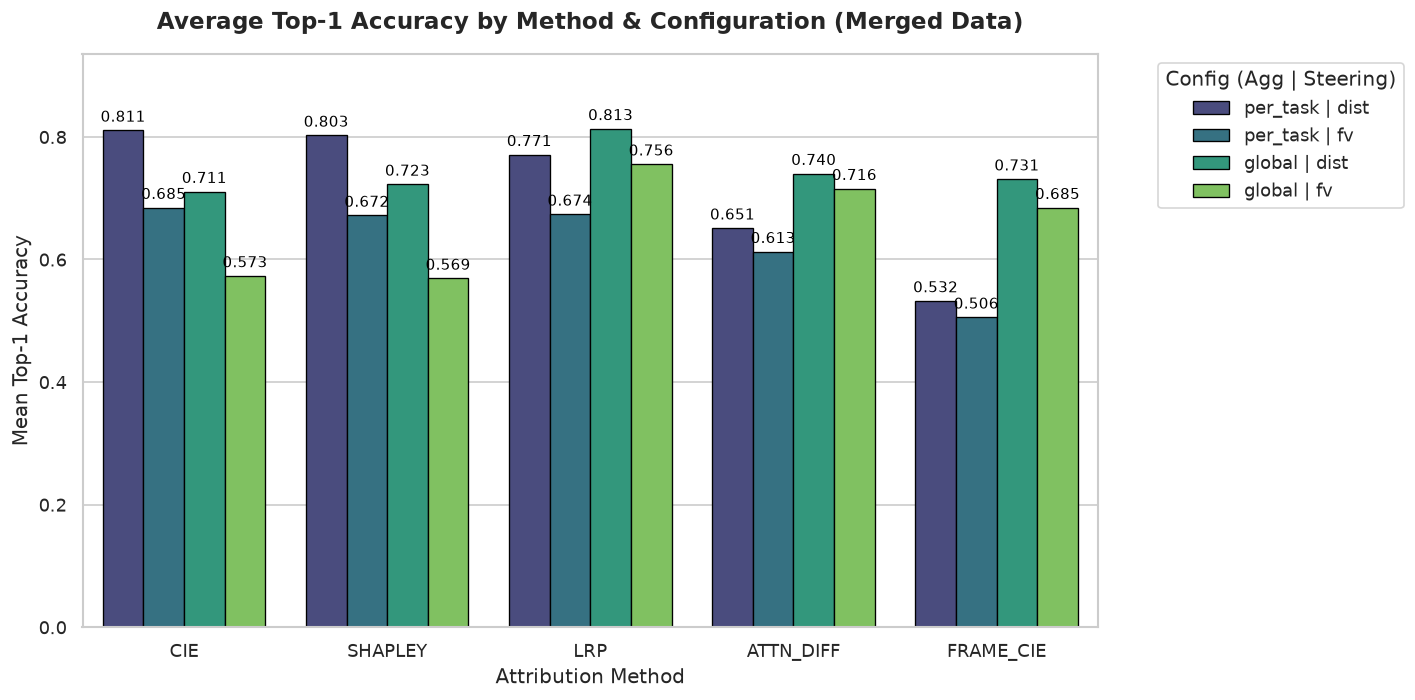

,Method,Aggregation,Steering,Scale,Avg Top-1,Task Count,Config
0,CIE,per_task,dist,1.0,0.810891,41,per_task | dist
1,CIE,per_task,fv,1.0,0.684765,41,per_task | fv
2,CIE,global,dist,1.0,0.710893,41,global | dist
3,CIE,global,fv,1.0,0.573317,41,global | fv
4,SHAPLEY,per_task,dist,1.0,0.802625,41,per_task | dist
5,SHAPLEY,per_task,fv,1.0,0.672010,41,per_task | fv
6,SHAPLEY,global,dist,1.0,0.722738,41,global | dist
7,SHAPLEY,global,fv,1.0,0.569224,41,global | fv
8,LRP,per_task,dist,1.0,0.771150,41,per_task | dist
9,LRP,per_task,fv,1.0,0.673836,41,per_task | fv


In [ ]:
def plot_merged_averages(data):
    results = data.get("results", {})
    run_scores = defaultdict(list)

    # Extract scores across the unified dataset
    for task, methods in results.items():
        for method, aggregations in methods.items():
            for agg, steerings in aggregations.items():
                for sm, scales in steerings.items():
                    for scale, metrics in scales.items():
                        if "top1" in metrics:
                            run_key = (method, agg, sm, scale)
                            run_scores[run_key].append(metrics["top1"])

    rows = []
    for key, scores in run_scores.items():
        method, agg, sm, scale = key
        rows.append({
            "Method": method.upper(),
            "Aggregation": agg,
            "Steering": sm,
            "Scale": float(scale),
            "Avg Top-1": sum(scores) / len(scores) if scores else 0,
            "Task Count": len(scores),
            "Config": f"{agg} | {sm}"
        })
        
    df = pd.DataFrame(rows)
    if df.empty:
        print("No results to plot.")
        return df

    # --- Plotting ---
    plt.figure(figsize=(12, 6), dpi=120)
    sns.set_theme(style="whitegrid")
    
    ax = sns.barplot(
        data=df,
        x="Method",
        y="Avg Top-1",
        hue="Config",
        palette="viridis",
        edgecolor="black",
        linewidth=0.8
    )

    # Add data labels on top of bars
    for p in ax.patches:
        height = p.get_height()
        if height > 0:
            ax.annotate(f'{height:.3f}',
                        (p.get_x() + p.get_width() / 2., height),
                        ha='center', va='bottom',
                        fontsize=9, color='black',
                        xytext=(0, 3), textcoords='offset points')

    plt.title("Average Top-1 Accuracy by Method & Configuration (Merged Data)", fontsize=14, fontweight='bold', pad=15)
    plt.ylabel("Mean Top-1 Accuracy", fontsize=12)
    plt.xlabel("Attribution Method", fontsize=12)
    plt.ylim(0, max(df["Avg Top-1"]) * 1.15)  # Leave room for labels
    plt.legend(title="Config (Agg | Steering)", bbox_to_anchor=(1.05, 1), loc='upper left', frameon=True)
    plt.tight_layout()
    plt.show()

    return df

df_averages = plot_merged_averages(eval_data)
display(df_averages)

In [ ]:
def compute_rank_aware_intersections(data, storage_root, prompt_length):
    if not data:
        return
        
    short_model_name = data.get("model", "Llama-3.2-3B-Instruct")
    prompt_type = data.get("prompt_type", "instruction")
    topk = data.get("topk_heads", 20)
    
    methods = ["cie", "shapley", "lrp","attn_diff","frame_cie"]
    global_scores = {}
# 1. Load and aggregate raw head scores across all tasks
    for method in methods:
        scores_list = []
        for task in TASKS:
            try:
                # Make sure 'utils' is actually imported in your script!
                save_dir = utils.result_dir(storage_root, short_model_name, task, prompt_length)
                scores_path = Path(save_dir) / f"{task}_{prompt_type}_{method}_head_scores.pt"
                
                if scores_path.exists():
                    s = torch.load(scores_path, map_location="cpu")
                    while s.dim() > 2:
                        s = s.mean(dim=0)
                    scores_list.append(s)
                else:
                    # Uncomment the line below to see exactly where it's looking
                    print(f"[Missing] Expected file here: {scores_path}")
                    pass
            except Exception as e:
                # THIS will tell you if it's a NameError, PermissionError, etc.
                print(f"[Error] Failed on task '{task}', method '{method}': {repr(e)}")
                continue

        if scores_list:
            global_scores[method] = torch.stack(scores_list).mean(dim=0)

    if not global_scores:
        print("No head scores could be loaded.")
        return

    # 2. Compute 1-based ranks for every head across the model (1 = Highest Score)
    ranks_dict = {}
    topk_heads_dict = {}
    
    for method, score_tensor in global_scores.items():
        flat_scores = score_tensor.flatten().numpy()
        # Get 1-based ranks (descending order)
        ranks = len(flat_scores) - np.argsort(np.argsort(flat_scores))
        ranks_dict[method] = ranks.reshape(score_tensor.shape)
        
        # Extract Top-K heads
        n_heads = score_tensor.shape[1]
        topk_idx = torch.topk(score_tensor.flatten(), k=topk).indices
        topk_heads_dict[method] = [(int(i) // n_heads, int(i) % n_heads) for i in topk_idx]

    # Helper 1: DataFrame for overlapping heads
    def get_overlap_df(m1, m2):
        top_m1 = set(topk_heads_dict[m1])
        top_m2 = set(topk_heads_dict[m2])
        overlap = top_m1.intersection(top_m2)
        
        rows = []
        for (l, h) in overlap:
            r1 = int(ranks_dict[m1][l, h])
            r2 = int(ranks_dict[m2][l, h])
            rows.append({
                "Head (L, H)": f"({l}, {h})",
                f"{m1.upper()} Rank": r1,
                f"{m2.upper()} Rank": r2,
                "Rank Delta": abs(r1 - r2)
            })
            
        df = pd.DataFrame(rows)
        if not df.empty:
            df = df.sort_values(by=f"{m1.upper()} Rank").reset_index(drop=True)
        return df

    # Helper 2: DataFrame for NON-overlapping heads in the Top-K
    def get_disjoint_df(m1, m2):
        top_m1 = set(topk_heads_dict[m1])
        top_m2 = set(topk_heads_dict[m2])
        
        m1_only = top_m1 - top_m2
        m2_only = top_m2 - top_m1
        
        rows = []
        for (l, h) in m1_only:
            r1 = int(ranks_dict[m1][l, h])
            r2 = int(ranks_dict[m2][l, h])
            rows.append({
                "Head (L, H)": f"({l}, {h})",
                "Source List": f"Top in {m1.upper()}",
                f"{m1.upper()} Rank": r1,
                f"{m2.upper()} Rank": r2,
                "Rank Delta": abs(r1 - r2)
            })
            
        for (l, h) in m2_only:
            r1 = int(ranks_dict[m1][l, h])
            r2 = int(ranks_dict[m2][l, h])
            rows.append({
                "Head (L, H)": f"({l}, {h})",
                "Source List": f"Top in {m2.upper()}",
                f"{m1.upper()} Rank": r1,
                f"{m2.upper()} Rank": r2,
                "Rank Delta": abs(r1 - r2)
            })
            
        df = pd.DataFrame(rows)
        if not df.empty:
            # Sort primarily by Source, then by the Rank Delta to see nearest misses first
            df = df.sort_values(by=["Source List", "Rank Delta"]).reset_index(drop=True)
        return df

    # 3. Print Rank Comparisons
    print(f"============================================================")
    print(f"             RANK-AWARE GLOBAL HEAD INTERSECTION            ")
    print(f"============================================================\n")

    for pair_a, pair_b in [("frame_cie", "lrp"), ("frame_cie", "cie"), ("lrp", "cie")]:
        df_overlap = get_overlap_df(pair_a, pair_b)
        df_disjoint = get_disjoint_df(pair_a, pair_b)
        overlap_count = len(df_overlap)
        
        # Calculate full-model Spearman & Kendall correlation
        flat_a = global_scores[pair_a].flatten().numpy()
        flat_b = global_scores[pair_b].flatten().numpy()
        rho, _ = spearmanr(flat_a, flat_b)
        tau, _ = kendalltau(flat_a, flat_b)

        print(f"--- {pair_a.upper()} vs {pair_b.upper()} ---")
        print(f"Top-{topk} Overlap Count: {overlap_count} / {topk} heads")
        print(f"Full-Model Spearman Correlation (rho): {rho:.4f}")
        print(f"Full-Model Kendall Rank Correlation (tau): {tau:.4f}\n")
        
        print(f"1. INTERSECTING HEADS (In BOTH Top-{topk}):")
        if not df_overlap.empty:
            display(df_overlap)
        else:
            print(f"No overlapping heads in Top-{topk}.\n")
            
        print(f"\n2. DISJOINT HEADS (In ONE Top-{topk} but not the other):")
        if not df_disjoint.empty:
            display(df_disjoint)
        else:
            print("Both methods produced the exact same set of Top heads.\n")
            
        print("*" * 60 + "\n")


compute_rank_aware_intersections(eval_data, STORAGE_ROOT, PROMPT_LENGTH)

No head scores could be loaded.


In [ ]:
def plot_paper_averages_from_dict(
    data,
    target_models=None,
    method_order=None,
    model_order=None,
    color_palette=None,
    output_name="average_eval_across_models_new.pdf"
):
    """
    Parses the nested dictionary across multiple models and plots the overall average
    Top-1 accuracy for each method per model using paper-ready styling.
    """
    results = data.get("results", {})
    raw_rows = []

    # 1. Iterate through the dictionary and filter based on conditions
    for model_name, tasks in results.items():
        # Match target models (e.g., Llama 3B and 8B)
        if target_models and not any(t in model_name for t in target_models):
            continue
            
        # Clean up model name for the plot
        display_model = model_name
        if "3.2-3B" in model_name: display_model = "Llama-3.2-3B"
        elif "3.1-8B" in model_name: display_model = "Llama-3.1-8B"

        for task, methods in tasks.items():
            for method, aggregations in methods.items():
                # Filter for extraction methods: CIE and LRP
                if method.lower() not in ['cie', 'lrp']:
                    continue
                    
                for agg, steerings in aggregations.items():
                    # Filter for global heads only
                    if agg.lower() != 'global':
                        continue
                        
                    for sm, scales in steerings.items():
                        sm_lower = sm.lower()
                        # Filter for steering: fv and dist fv
                        if 'fv' not in sm_lower:
                            continue
                            
                        # Create Display Name (e.g., "CIE + dist. FV")
                        method_display = method.upper()
                        steering_display = "dist. FV" if "dist" in sm_lower else "FV"
                        display_name = f"{method_display} + {steering_display}"

                        for scale, metrics in scales.items():
                            if "top1" in metrics:
                                # Standardize scale extraction (assuming default scale 1.0)
                                if str(scale) in ["1.0", "1", 1.0]:
                                    raw_rows.append({
                                        'Task': task,
                                        'Method': display_name,
                                        'Top-1 Accuracy': metrics["top1"],
                                        'Model': display_model
                                    })

    if not raw_rows:
        print("No data found matching the specified filters.")
        return None

    # 2. Calculate average across tasks for each model and method
    df_raw = pd.DataFrame(raw_rows)
    avg_df = df_raw.groupby(['Model', 'Method'])['Top-1 Accuracy'].mean().reset_index()

    # 3. Ensure order for the legend and bars
    if method_order:
        avg_df['Method'] = pd.Categorical(
            avg_df['Method'], categories=method_order, ordered=True
        )
    if model_order:
        avg_df['Model'] = pd.Categorical(
            avg_df['Model'], categories=model_order, ordered=True
        )

    # Sort to keep things organized
    avg_df = avg_df.sort_values(['Model', 'Method'])
    print(avg_df)

    # 4. Plotting
    plt.figure(figsize=(10, 6))
    sns.set_style("whitegrid")

    plot = sns.barplot(
        data=avg_df,
        x='Model',
        y='Top-1 Accuracy',
        hue='Method',
        palette=color_palette,
        hue_order=method_order,
        order=model_order
    )

    plt.ylim(0, 1)

    # Increase label text sizes and make them bold
    plt.ylabel('Accuracy', fontsize=22, fontweight='bold')
    plt.xlabel('Model', fontsize=22, fontweight='bold')

    # Increase tick mark text sizes
    plt.xticks(fontsize=20)
    plt.yticks(fontsize=18)

    # Move legend to the top
    # Using ncol=2 to match your comment "2x2 grid", though you had ncol=4 in the original code. 
    # Change to 4 if you prefer them all on one row!
    plt.legend(
        bbox_to_anchor=(0.45, 1.03),  # Centered above the plot
        loc='lower center',
        ncol=2,                       # 2x2 grid
        frameon=True,
        fontsize=17,                  # Larger legend text
        title_fontsize=16.5,          # Larger legend title text
        columnspacing=0.8,            # Space between columns
        handletextpad=0.4,            # Space between the line/marker and the text
        borderpad=0.4
    )

    plt.tight_layout()
    plt.savefig(output_name, dpi=300)
    print(f"Plot saved successfully as {output_name}")
    plt.show()
    
    return avg_df

# --- Configuration for Execution ---

# Extract only models containing these strings
my_target_models = ["3.2-3B", "3.1-8B"]

# Model rendering order on the X-axis
my_model_order = [
    "Llama-3.2-3B",
    "Llama-3.1-8B"
]

# Order and naming (Updated AIE -> CIE based on prompt)
my_order = [
    "LRP + dist. FV",
    "CIE + dist. FV",
    "LRP + FV",
    "CIE + FV",
]

# Standardized Colors
my_colors = {
    "CIE + dist. FV": "#007BFF",  # Bright Electric Blue
    "LRP + dist. FV": "#28A745",  # Vibrant Leaf Green
    "CIE + FV":       "#80BCFF",  # Light Sky Blue
    "LRP + FV":       "#94D6A2"   # Light Mint Green
}

# --- Execution ---
# Assuming `eval_data` is the merged dictionary from the previous step
df_paper = plot_paper_averages_from_dict(
    data=eval_data,
    target_models=my_target_models,
    method_order=my_order,
    model_order=my_model_order,
    color_palette=my_colors,
    output_name="average_eval_across_llama_models_new.pdf"
)

No data found matching the specified filters.


In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

def plot_paper_averages_from_dict(
    data,
    target_models=None,
    method_order=None,
    model_order=None,
    color_palette=None,
    output_name="average_eval_across_models_new.pdf"
):
    """
    Parses the nested dictionary across multiple models and plots the overall average
    Top-1 accuracy for each method per model using paper-ready styling.
    """
    results = data.get("results", {})
    raw_rows = []

    # 1. Iterate through the dictionary and filter based on conditions
    for model_name, tasks in results.items():
        # Match target models (e.g., Llama 3B and 8B)
        if target_models and not any(t in model_name for t in target_models):
            continue
            
        # Clean up model name for the plot
        display_model = model_name
        if "3.2-3B" in model_name: display_model = "Llama-3.2-3B"
        elif "3.1-8B" in model_name: display_model = "Llama-3.1-8B"

        # In your merged data, results[model_name] contains tasks
        for task, methods in tasks.items():
            for method, aggregations in methods.items():
                
                # Standardize method names for display
                method_lower = method.lower()
                if method_lower == 'if_patching':
                    method_display = 'IF'
                elif method_lower == 'cie':
                    method_display = 'CIE'
                elif method_lower == 'lrp':
                    method_display = 'LRP'
                else:
                    continue  # Skip any other extraction methods
                    
                for agg, steerings in aggregations.items():
                    # Filter: only plot global heads
                    if agg.lower() != 'global':
                        continue
                        
                    for sm, scales in steerings.items():
                        sm_lower = sm.lower()
                        
                        # Determine steering display name
                        if sm_lower == 'dist':
                            steering_display = "dist. FV"
                        elif sm_lower == 'fv':
                            steering_display = "FV"
                        else:
                            continue # Skip other steering types
                            
                        # Create Display Name (e.g., "IF + dist. FV")
                        display_name = f"{method_display} + {steering_display}"

                        for scale, metrics in scales.items():
                            if "top1" in metrics:
                                # Standardize scale extraction (assuming default scale 1.0)
                                if str(scale) in ["1.0", "1", 1.0]:
                                    raw_rows.append({
                                        'Task': task,
                                        'Method': display_name,
                                        'Top-1 Accuracy': metrics["top1"],
                                        'Model': display_model
                                    })

    if not raw_rows:
        print("No data found matching the specified filters.")
        return None

    # 2. Calculate average across tasks for each model and method
    df_raw = pd.DataFrame(raw_rows)
    avg_df = df_raw.groupby(['Model', 'Method'])['Top-1 Accuracy'].mean().reset_index()

    # 3. Ensure order for the legend and bars
    if method_order:
        avg_df['Method'] = pd.Categorical(
            avg_df['Method'], categories=method_order, ordered=True
        )
    if model_order:
        avg_df['Model'] = pd.Categorical(
            avg_df['Model'], categories=model_order, ordered=True
        )

    # Sort to keep things organized
    avg_df = avg_df.sort_values(['Model', 'Method']).dropna()
    print("Aggregated Averages:")
    print(avg_df)

    # 4. Plotting
    plt.figure(figsize=(12, 6)) # slightly wider for 3 methods
    sns.set_style("whitegrid")

    plot = sns.barplot(
        data=avg_df,
        x='Model',
        y='Top-1 Accuracy',
        hue='Method',
        palette=color_palette,
        hue_order=method_order,
        order=model_order
    )

    plt.ylim(0, 1)

    # Increase label text sizes and make them bold
    plt.ylabel('Accuracy', fontsize=22, fontweight='bold')
    plt.xlabel('Model', fontsize=22, fontweight='bold')

    # Increase tick mark text sizes
    plt.xticks(fontsize=20)
    plt.yticks(fontsize=18)

    # Move legend to the top (ncol=3 for a nice 3x2 grid layout)
    plt.legend(
        bbox_to_anchor=(0.5, 1.03),  # Centered above the plot
        loc='lower center',
        ncol=3,                      # 3 columns for 6 methods
        frameon=True,
        fontsize=17,
        title_fontsize=16.5,
        columnspacing=0.8,
        handletextpad=0.4,
        borderpad=0.4
    )

    plt.tight_layout()
    plt.savefig(output_name, dpi=300)
    print(f"Plot saved successfully as {output_name}")
    plt.show()
    
    return avg_df

# --- Configuration for Execution ---

# Extract only models containing these strings
my_target_models = ["3.2-3B", "3.1-8B"]

# Model rendering order on the X-axis
my_model_order = [
    "Llama-3.2-3B",
    "Llama-3.1-8B"
]

# Order for Legend and Bars
my_order = [
    "LRP + dist. FV",
    "CIE + dist. FV",
    "IF + dist. FV",
    "LRP + FV",
    "CIE + FV",
    "IF + FV",
]

# Standardized Colors with two new Purple shades for IF Patching
my_colors = {
    "CIE + dist. FV": "#007BFF",  # Bright Electric Blue
    "CIE + FV":       "#80BCFF",  # Light Sky Blue
    "LRP + dist. FV": "#28A745",  # Vibrant Leaf Green
    "LRP + FV":       "#94D6A2",  # Light Mint Green
    "IF + dist. FV":  "#6F42C1",  # Deep Vibrant Purple
    "IF + FV":        "#B19CD9"   # Soft Light Purple
}

# --- Execution ---
# Assumes `eval_data` is your loaded unified dictionary
df_paper = plot_paper_averages_from_dict(
    data=eval_data, 
    target_models=my_target_models,
    method_order=my_order,
    model_order=my_model_order,
    color_palette=my_colors,
    output_name="average_eval_with_if_patching.pdf"
)

No data found matching the specified filters.


In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

def plot_paper_averages_from_dict(
    data,
    target_models=None,
    method_order=None,
    model_order=None,
    color_palette=None,
    output_name="average_eval_with_if_patching.pdf"
):
    results = data.get("results", {})
    raw_rows = []
    
    # --- DIAGNOSTIC CHECK ---
    first_keys = list(results.keys())[:3]
    print(f"DEBUG: First level keys in results: {first_keys}")
    
    # If the first key is a known task like 'antonym', the dictionary isn't nested by model!
    is_nested_by_model = not any(k in ['antonym', 'next_item', 'singular-plural'] for k in first_keys)
    
    # 1. Iterate through the dictionary
    # Handle both nested (results -> model -> task) and flat (results -> task, model is top-level)
    for key1, val1 in results.items():
        if is_nested_by_model:
            model_name = key1
            tasks_dict = val1
        else:
            model_name = data.get("model", "Unknown Model")
            # If it's flat, we need to wrap it to iterate properly
            tasks_dict = {key1: val1} 
            
        # Match target models
        if target_models and not any(t in model_name for t in target_models):
            continue
            
        # Clean up model name for the plot
        display_model = model_name
        if "3.2-3B" in model_name: display_model = "Llama-3.2-3B"
        elif "3.1-8B" in model_name: display_model = "Llama-3.1-8B"

        for task, methods in tasks_dict.items():
            for method, aggregations in methods.items():
                
                # Standardize method names for display
                method_lower = method.lower()
                if method_lower == 'if_patching':
                    method_display = 'IF'
                elif method_lower in ['cie', 'ie']:  # Catch 'ie' just in case it wasn't renamed in JSON
                    method_display = 'CIE'
                elif method_lower == 'lrp':
                    method_display = 'LRP'
                else:
                    continue  # Skip unknown methods
                    
                for agg, steerings in aggregations.items():
                    # Filter: only plot global heads
                    if agg.lower() != 'global':
                        continue
                        
                    for sm, scales in steerings.items():
                        sm_lower = sm.lower()
                        
                        # Determine steering display name (FIXED THE BUG HERE)
                        if sm_lower == 'dist':
                            steering_display = "dist. FV"
                        elif sm_lower == 'fv':
                            steering_display = "FV"
                        else:
                            continue # Skip other steering types
                            
                        display_name = f"{method_display} + {steering_display}"

                        for scale, metrics in scales.items():
                            if "top1" in metrics:
                                if str(scale) in ["1.0", "1", 1.0]:
                                    raw_rows.append({
                                        'Task': task,
                                        'Method': display_name,
                                        'Top-1 Accuracy': metrics["top1"],
                                        'Model': display_model
                                    })

    if not raw_rows:
        print("\nERROR: No data found matching the specified filters!")
        print(f"Target Models Looked For: {target_models}")
        print("Please check the console output above to see the top-level keys.")
        return None

    df_raw = pd.DataFrame(raw_rows)
    avg_df = df_raw.groupby(['Model', 'Method'])['Top-1 Accuracy'].mean().reset_index()

    if method_order:
        avg_df['Method'] = pd.Categorical(avg_df['Method'], categories=method_order, ordered=True)
    if model_order:
        avg_df['Model'] = pd.Categorical(avg_df['Model'], categories=model_order, ordered=True)

    avg_df = avg_df.sort_values(['Model', 'Method']).dropna()
    print("\nSUCCESS! Aggregated Averages found:")
    print(avg_df)

    # 4. Plotting
    plt.figure(figsize=(12, 6)) 
    sns.set_style("whitegrid")

    plot = sns.barplot(
        data=avg_df, x='Model', y='Top-1 Accuracy', hue='Method',
        palette=color_palette, hue_order=method_order, order=model_order
    )
    plt.ylim(0, 1)
    plt.ylabel('Accuracy', fontsize=22, fontweight='bold')
    plt.xlabel('Model', fontsize=22, fontweight='bold')
    plt.xticks(fontsize=20)
    plt.yticks(fontsize=18)
    
    plt.legend(
        bbox_to_anchor=(0.5, 1.03), loc='lower center', ncol=3,
        frameon=True, fontsize=17, title_fontsize=16.5,
        columnspacing=0.8, handletextpad=0.4, borderpad=0.4
    )
    plt.tight_layout()
    plt.savefig(output_name, dpi=300)
    plt.show()
    
    return avg_df

# --- Configuration for Execution ---

# Extract only models containing these strings
my_target_models = ["3.2-3B", "3.1-8B"]

my_model_order = ["Llama-3.2-3B", "Llama-3.1-8B"]

my_order = [
    "LRP + dist. FV", "CIE + dist. FV", "IF + dist. FV",
    "LRP + FV", "CIE + FV", "IF + FV"
]

my_colors = {
    "CIE + dist. FV": "#007BFF",  
    "CIE + FV":       "#80BCFF",  
    "LRP + dist. FV": "#28A745",  
    "LRP + FV":       "#94D6A2",  
    "IF + dist. FV":  "#6F42C1",  
    "IF + FV":        "#B19CD9"   
}

# RUN THE PLOT
df_paper = plot_paper_averages_from_dict(
    data=eval_data, 
    target_models=my_target_models,
    method_order=my_order,
    model_order=my_model_order,
    color_palette=my_colors,
    output_name="average_eval_with_if_patching.pdf"
)

DEBUG: First level keys in results: ['antonym', 'capitalize', 'capitalize_first_letter']

ERROR: No data found matching the specified filters!
Target Models Looked For: ['3.2-3B', '3.1-8B']
Please check the console output above to see the top-level keys.


In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

def plot_paper_averages_from_dict(
    data,
    target_models=None,
    method_order=None,
    model_order=None,
    color_palette=None,
    output_name="average_eval_with_if_patching.pdf"
):
    results = data.get("results", {})
    raw_rows = []
    
    # --- DIAGNOSTIC CHECK ---
    first_keys = list(results.keys())[:3]
    print(f"DEBUG: First level keys in results: {first_keys}")
    
    # If the first key is a known task like 'antonym', the dictionary isn't nested by model!
    is_nested_by_model = not any(k in ['antonym', 'next_item', 'singular-plural'] for k in first_keys)
    
    # 1. Iterate through the dictionary
    # Handle both nested (results -> model -> task) and flat (results -> task, model is top-level)
    for key1, val1 in results.items():
        if is_nested_by_model:
            model_name = key1
            tasks_dict = val1
        else:
            model_name = data.get("model", "Unknown Model")
            # If it's flat, we need to wrap it to iterate properly
            tasks_dict = {key1: val1} 
            
        # Match target models
        if target_models and not any(t in model_name for t in target_models):
            continue
            
        # Clean up model name for the plot
        display_model = model_name
        if "3.2-3B" in model_name: display_model = "Llama-3.2-3B"
        elif "3.1-8B" in model_name: display_model = "Llama-3.1-8B"

        for task, methods in tasks_dict.items():
            for method, aggregations in methods.items():
                
                # Standardize method names for display
                method_lower = method.lower()
                if method_lower == 'if_patching':
                    method_display = 'IF'
                elif method_lower in ['cie', 'ie']:  # Catch 'ie' just in case it wasn't renamed in JSON
                    method_display = 'CIE'
                elif method_lower == 'lrp':
                    method_display = 'LRP'
                else:
                    continue  # Skip unknown methods
                    
                for agg, steerings in aggregations.items():
                    # Filter: only plot global heads
                    if agg.lower() != 'global':
                        continue
                        
                    for sm, scales in steerings.items():
                        sm_lower = sm.lower()
                        
                        # Determine steering display name (FIXED THE BUG HERE)
                        if sm_lower == 'dist':
                            steering_display = "dist. FV"
                        elif sm_lower == 'fv':
                            steering_display = "FV"
                        else:
                            continue # Skip other steering types
                            
                        display_name = f"{method_display} + {steering_display}"

                        for scale, metrics in scales.items():
                            if "top1" in metrics:
                                if str(scale) in ["1.0", "1", 1.0]:
                                    raw_rows.append({
                                        'Task': task,
                                        'Method': display_name,
                                        'Top-1 Accuracy': metrics["top1"],
                                        'Model': display_model
                                    })

    if not raw_rows:
        print("\nERROR: No data found matching the specified filters!")
        print(f"Target Models Looked For: {target_models}")
        print("Please check the console output above to see the top-level keys.")
        return None

    df_raw = pd.DataFrame(raw_rows)
    avg_df = df_raw.groupby(['Model', 'Method'])['Top-1 Accuracy'].mean().reset_index()

    if method_order:
        avg_df['Method'] = pd.Categorical(avg_df['Method'], categories=method_order, ordered=True)
    if model_order:
        avg_df['Model'] = pd.Categorical(avg_df['Model'], categories=model_order, ordered=True)

    avg_df = avg_df.sort_values(['Model', 'Method']).dropna()
    print("\nSUCCESS! Aggregated Averages found:")
    print(avg_df)

    # 4. Plotting
    plt.figure(figsize=(12, 6)) 
    sns.set_style("whitegrid")

    plot = sns.barplot(
        data=avg_df, x='Model', y='Top-1 Accuracy', hue='Method',
        palette=color_palette, hue_order=method_order, order=model_order
    )
    plt.ylim(0, 1)
    plt.ylabel('Accuracy', fontsize=22, fontweight='bold')
    plt.xlabel('Model', fontsize=22, fontweight='bold')
    plt.xticks(fontsize=20)
    plt.yticks(fontsize=18)
    
    plt.legend(
        bbox_to_anchor=(0.5, 1.03), loc='lower center', ncol=3,
        frameon=True, fontsize=17, title_fontsize=16.5,
        columnspacing=0.8, handletextpad=0.4, borderpad=0.4
    )
    plt.tight_layout()
    plt.savefig(output_name, dpi=300)
    plt.show()
    
    return avg_df

# --- Configuration for Execution ---

# Extract only models containing these strings
my_target_models = ["3.2-3B", "3.1-8B"]

my_model_order = ["Llama-3.2-3B", "Llama-3.1-8B"]

my_order = [
    "LRP + dist. FV", "CIE + dist. FV", "IF + dist. FV",
    "LRP + FV", "CIE + FV", "IF + FV"
]

my_colors = {
    "CIE + dist. FV": "#007BFF",  
    "CIE + FV":       "#80BCFF",  
    "LRP + dist. FV": "#28A745",  
    "LRP + FV":       "#94D6A2",  
    "IF + dist. FV":  "#6F42C1",  
    "IF + FV":        "#B19CD9"   
}

# RUN THE PLOT
df_paper = plot_paper_averages_from_dict(
    data=eval_data, 
    target_models=my_target_models,
    method_order=my_order,
    model_order=my_model_order,
    color_palette=my_colors,
    output_name="average_eval_with_if_patching.pdf"
)

NameError: name 'eval_data' is not defined

DEBUG: Found single model in data: Qwen3-4B-Instruct-2507

SUCCESS! Aggregated Averages found:
      Model          Method  Top-1 Accuracy
5  Qwen3-4B  LRP + dist. FV        0.602376
1  Qwen3-4B  CIE + dist. FV        0.710893
3  Qwen3-4B   IF + dist. FV        0.783106
4  Qwen3-4B        LRP + FV        0.518493
0  Qwen3-4B        CIE + FV        0.573317
2  Qwen3-4B         IF + FV        0.714723


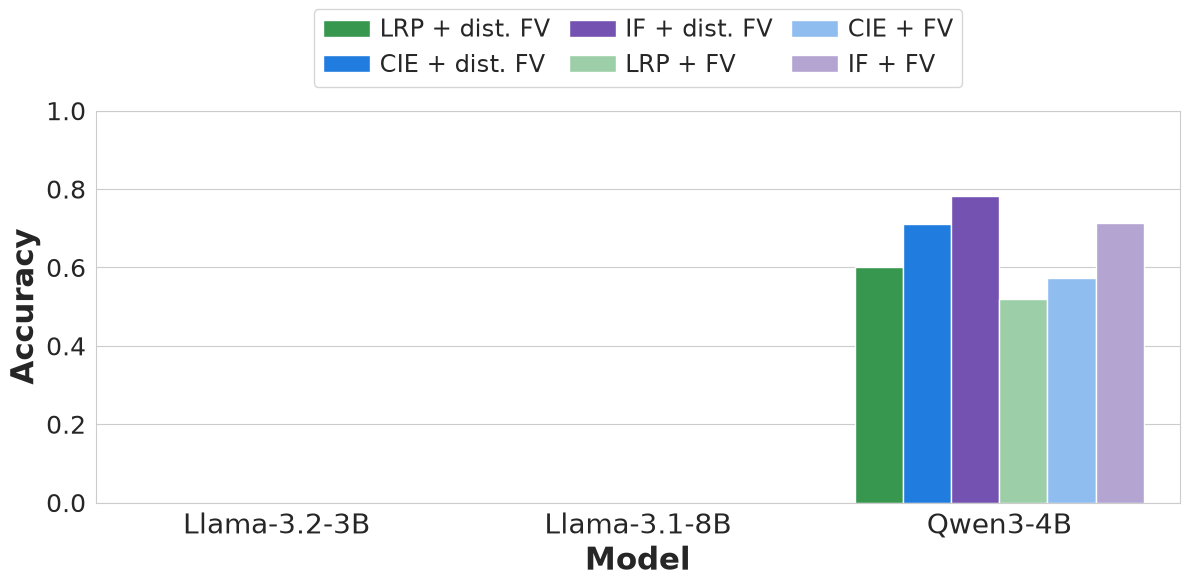

In [ ]:
eval_data

Found 11 files. Extracting data...

SUCCESS! Data successfully separated by model:
           Model          Method  Top-1 Accuracy
11  Llama-3.2-3B  LRP + dist. FV        0.813410
7   Llama-3.2-3B  CIE + dist. FV        0.710893
9   Llama-3.2-3B   IF + dist. FV        0.783106
10  Llama-3.2-3B        LRP + FV        0.755670
6   Llama-3.2-3B        CIE + FV        0.573317
8   Llama-3.2-3B         IF + FV        0.714723
5   Llama-3.1-8B  LRP + dist. FV        0.755555
1   Llama-3.1-8B  CIE + dist. FV        0.600447
3   Llama-3.1-8B   IF + dist. FV        0.716905
4   Llama-3.1-8B        LRP + FV        0.578677
0   Llama-3.1-8B        CIE + FV        0.392966
2   Llama-3.1-8B         IF + FV        0.485433
13      Qwen3-4B  LRP + dist. FV        0.602376
12      Qwen3-4B        LRP + FV        0.518493


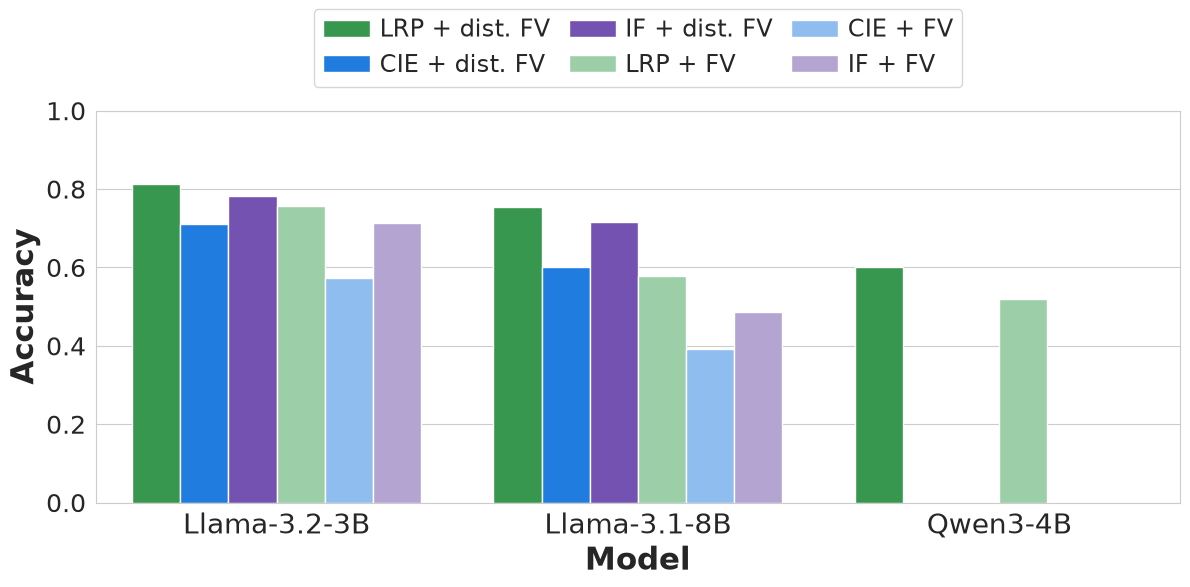

In [2]:
import os
import glob
import json
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

def load_and_plot_directly(
    file_pattern="results/*_eval_all_*.json",  # UPDATE THIS IF YOUR PATH IS DIFFERENT
    output_name="average_eval_with_if_patching.pdf"
):
    # 1. Find all files
    files = glob.glob(file_pattern, recursive=True)
    if not files:
        print(f"ERROR: No files found matching: {file_pattern}")
        return None
        
    print(f"Found {len(files)} files. Extracting data...")
    raw_rows = []
    
    # 2. Read straight from files to avoid the merging bug
    for fpath in files:
        with open(fpath, 'r') as f:
            data = json.load(f)
            
        # Grab model name from the file's JSON
        model_name = data.get("model", "Unknown Model")
        
        # Standardize model names
        display_model = None
        if "3.2-3B" in model_name: display_model = "Llama-3.2-3B"
        elif "3.1-8B" in model_name: display_model = "Llama-3.1-8B"
        elif "Qwen3-4B" in model_name: display_model = "Qwen3-4B"
        
        # If it's not one of our target models, skip it
        if not display_model:
            continue
            
        results = data.get("results", {})
        for task, methods in results.items():
            for method, aggregations in methods.items():
                
                # Standardize method names
                method_lower = method.lower()
                if method_lower == 'if_patching': method_display = 'IF'
                elif method_lower in ['cie', 'ie']: method_display = 'CIE'
                elif method_lower == 'lrp': method_display = 'LRP'
                else: continue
                    
                for agg, steerings in aggregations.items():
                    # FILTER: Only global heads
                    if agg.lower() != 'global': continue
                        
                    for sm, scales in steerings.items():
                        sm_lower = sm.lower()
                        if sm_lower == 'dist': steering_display = "dist. FV"
                        elif sm_lower == 'fv': steering_display = "FV"
                        else: continue
                            
                        display_name = f"{method_display} + {steering_display}"
                        
                        for scale, metrics in scales.items():
                            # Extract Scale 1.0 Top-1
                            if "top1" in metrics and str(scale) in ["1.0", "1", 1.0]:
                                raw_rows.append({
                                    'Task': task,
                                    'Method': display_name,
                                    'Top-1 Accuracy': metrics["top1"],
                                    'Model': display_model
                                })

    # 3. Create DataFrame and Average
    df_raw = pd.DataFrame(raw_rows)
    if df_raw.empty:
        print("ERROR: Files were found, but no matching configurations (global/dist/fv/scale 1.0) were inside.")
        return df_raw
        
    avg_df = df_raw.groupby(['Model', 'Method'])['Top-1 Accuracy'].mean().reset_index()
    
    # 4. Enforce Ordering
    model_order = ["Llama-3.2-3B", "Llama-3.1-8B", "Qwen3-4B"]
    method_order = [
        "LRP + dist. FV", "CIE + dist. FV", "IF + dist. FV",
        "LRP + FV",       "CIE + FV",       "IF + FV"
    ]
    
    # Filter the order lists to only include what we actually found in the data
    found_models = [m for m in model_order if m in avg_df['Model'].values]
    found_methods = [m for m in method_order if m in avg_df['Method'].values]
    
    avg_df['Model'] = pd.Categorical(avg_df['Model'], categories=found_models, ordered=True)
    avg_df['Method'] = pd.Categorical(avg_df['Method'], categories=found_methods, ordered=True)
    avg_df = avg_df.sort_values(['Model', 'Method']).dropna()
    
    print("\nSUCCESS! Data successfully separated by model:")
    print(avg_df)

    # 5. The Colors (Collards) - includes the 2 new Purples for IF
    my_colors = {
        "CIE + dist. FV": "#007BFF",  # Bright Electric Blue
        "CIE + FV":       "#80BCFF",  # Light Sky Blue
        "LRP + dist. FV": "#28A745",  # Vibrant Leaf Green
        "LRP + FV":       "#94D6A2",  # Light Mint Green
        "IF + dist. FV":  "#6F42C1",  # Deep Vibrant Purple
        "IF + FV":        "#B19CD9"   # Soft Light Purple
    }

    # 6. Plotting
    plt.figure(figsize=(12, 6)) 
    sns.set_style("whitegrid")

    plot = sns.barplot(
        data=avg_df, x='Model', y='Top-1 Accuracy', hue='Method',
        palette=my_colors, hue_order=found_methods, order=found_models
    )
    
    plt.ylim(0, 1)
    plt.ylabel('Accuracy', fontsize=22, fontweight='bold')
    plt.xlabel('Model', fontsize=22, fontweight='bold')
    plt.xticks(fontsize=20)
    plt.yticks(fontsize=18)
    
    plt.legend(
        bbox_to_anchor=(0.5, 1.03), loc='lower center', ncol=3,
        frameon=True, fontsize=17, title_fontsize=16.5,
        columnspacing=0.8, handletextpad=0.4, borderpad=0.4
    )
    plt.tight_layout()
    plt.savefig(output_name, dpi=300)
    plt.show()
    
    return avg_df

# --- EXECUTE ---
# Note: Update the path string below if your JSON files are stored in a different folder!
df_final = load_and_plot_directly(
    file_pattern="results/*_eval_all_*.json", 
    output_name="average_eval_with_if_patching.pdf"
)

Using provided list of 9 files.

SUCCESS! Data successfully separated by model:
           Model          Method  Top-1 Accuracy
11  Llama-3.2-3B  LRP + dist. FV        0.813410
7   Llama-3.2-3B  CIE + dist. FV        0.710893
9   Llama-3.2-3B   IF + dist. FV        0.783106
10  Llama-3.2-3B        LRP + FV        0.755670
6   Llama-3.2-3B        CIE + FV        0.573317
8   Llama-3.2-3B         IF + FV        0.714723
5   Llama-3.1-8B  LRP + dist. FV        0.755555
1   Llama-3.1-8B  CIE + dist. FV        0.616629
3   Llama-3.1-8B   IF + dist. FV        0.720884
4   Llama-3.1-8B        LRP + FV        0.578677
0   Llama-3.1-8B        CIE + FV        0.470697
2   Llama-3.1-8B         IF + FV        0.643357
17      Qwen3-4B  LRP + dist. FV        0.602376
13      Qwen3-4B  CIE + dist. FV        0.526722
15      Qwen3-4B   IF + dist. FV        0.540843
16      Qwen3-4B        LRP + FV        0.518493
12      Qwen3-4B        CIE + FV        0.451701
14      Qwen3-4B         IF + FV      

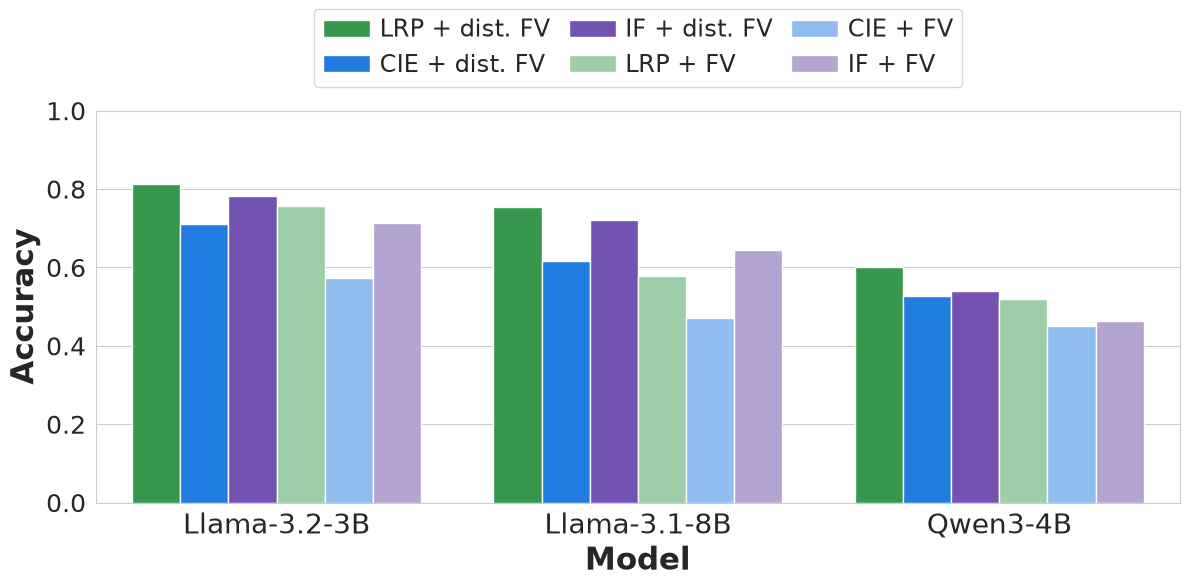

In [1]:
import os
import glob
import json
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

def load_and_plot_directly(
    file_pattern=None,
    file_paths=None,
    output_name="average_eval_with_if_patching.pdf"
):
    # 1. Determine which files to load
    if file_paths is not None:
        files = file_paths  # Use the exact list provided
        print(f"Using provided list of {len(files)} files.")
    elif file_pattern is not None:
        files = glob.glob(file_pattern, recursive=True) # Fallback to folder search
        print(f"Found {len(files)} files matching pattern.")
    else:
        print("ERROR: You must provide either 'file_pattern' or 'file_paths'.")
        return None

    if not files:
        print("ERROR: No files to process.")
        return None
        
    raw_rows = []
    
    # 2. Read straight from files
    for fpath in files:
        if not os.path.exists(fpath):
            print(f"Warning: File not found and skipped: {fpath}")
            continue
            
        with open(fpath, 'r') as f:
            data = json.load(f)
            
        model_name = data.get("model", "Unknown Model")
        
        display_model = None
        if "3.2-3B" in model_name: display_model = "Llama-3.2-3B"
        elif "3.1-8B" in model_name: display_model = "Llama-3.1-8B"
        elif "Qwen3-4B" in model_name: display_model = "Qwen3-4B"
        
        if not display_model:
            continue
            
        results = data.get("results", {})
        for task, methods in results.items():
            for method, aggregations in methods.items():
                
                method_lower = method.lower()
                if method_lower == 'if_patching': method_display = 'IF'
                elif method_lower in ['cie', 'ie']: method_display = 'CIE'
                elif method_lower == 'lrp': method_display = 'LRP'
                else: continue
                    
                for agg, steerings in aggregations.items():
                    if agg.lower() != 'global': continue
                        
                    for sm, scales in steerings.items():
                        sm_lower = sm.lower()
                        if sm_lower == 'dist': steering_display = "dist. FV"
                        elif sm_lower == 'fv': steering_display = "FV"
                        else: continue
                            
                        display_name = f"{method_display} + {steering_display}"
                        
                        for scale, metrics in scales.items():
                            if "top1" in metrics and str(scale) in ["1.0", "1", 1.0]:
                                raw_rows.append({
                                    'Task': task,
                                    'Method': display_name,
                                    'Top-1 Accuracy': metrics["top1"],
                                    'Model': display_model
                                })

    # 3. Create DataFrame and Handle Duplicates
    df_raw = pd.DataFrame(raw_rows)
    if df_raw.empty:
        print("ERROR: Files were loaded, but no matching configurations were inside.")
        return df_raw
        
    # Optional: Keep the highest accuracy if there are duplicates of the same task
    df_raw = df_raw.sort_values('Top-1 Accuracy', ascending=False)
    df_raw = df_raw.drop_duplicates(subset=['Model', 'Task', 'Method'], keep='first')
        
    avg_df = df_raw.groupby(['Model', 'Method'])['Top-1 Accuracy'].mean().reset_index()
    
    # 4. Enforce Ordering
    model_order = ["Llama-3.2-3B", "Llama-3.1-8B", "Qwen3-4B"]
    method_order = [
        "LRP + dist. FV", "CIE + dist. FV", "IF + dist. FV",
        "LRP + FV",       "CIE + FV",       "IF + FV"
    ]
    
    found_models = [m for m in model_order if m in avg_df['Model'].values]
    found_methods = [m for m in method_order if m in avg_df['Method'].values]
    
    avg_df['Model'] = pd.Categorical(avg_df['Model'], categories=found_models, ordered=True)
    avg_df['Method'] = pd.Categorical(avg_df['Method'], categories=found_methods, ordered=True)
    avg_df = avg_df.sort_values(['Model', 'Method']).dropna()
    
    print("\nSUCCESS! Data successfully separated by model:")
    print(avg_df)

    # 5. The Colors (Collards)
    my_colors = {
        "CIE + dist. FV": "#007BFF",  
        "CIE + FV":       "#80BCFF",  
        "LRP + dist. FV": "#28A745",  
        "LRP + FV":       "#94D6A2",  
        "IF + dist. FV":  "#6F42C1",  
        "IF + FV":        "#B19CD9"   
    }

    # 6. Plotting
    plt.figure(figsize=(12, 6)) 
    sns.set_style("whitegrid")

    plot = sns.barplot(
        data=avg_df, x='Model', y='Top-1 Accuracy', hue='Method',
        palette=my_colors, hue_order=found_methods, order=found_models
    )
    
    plt.ylim(0, 1)
    plt.ylabel('Accuracy', fontsize=22, fontweight='bold')
    plt.xlabel('Model', fontsize=22, fontweight='bold')
    plt.xticks(fontsize=20)
    plt.yticks(fontsize=18)
    
    plt.legend(
        bbox_to_anchor=(0.5, 1.03), loc='lower center', ncol=3,
        frameon=True, fontsize=17, title_fontsize=16.5,
        columnspacing=0.8, handletextpad=0.4, borderpad=0.4
    )
    plt.tight_layout()
    plt.savefig(output_name, dpi=300)
    plt.show()
    
    return avg_df

# --- EXECUTE WITH EXPLICIT PATHS ---
my_specific_files = [
    "results/Llama-3.2-3B-Instruct_eval_all_20260722_150641.json",
    "results/Llama-3.2-3B-Instruct_eval_all_20260724_145349.json",
    "results/Llama-3.1-8B-Instruct_eval_all_20260729_153706.json",
    "results/Llama-3.1-8B-Instruct_eval_all_20260731_155008.json",
    "results/Qwen3-4B-Instruct-2507_eval_all_20260729_201355.json",
    "results/Qwen3-4B-Instruct-2507_eval_all_20260731_160909.json",
    "results/Llama-3.1-8B-Instruct_eval_all_20260731_164529.json",
    "results/Llama-3.1-8B-Instruct_eval_all_20260731_170401.json",
    "results/Llama-3.1-8B-Instruct_eval_all_20260731_171603.json"
    ]

df_final = load_and_plot_directly(
    file_paths=my_specific_files, 
    output_name="average_eval_with_if_patching.pdf"
)

Precomputing global heads across all tasks...
  ✓ Found 20 global top heads for 'cie'
  ✓ Found 20 global top heads for 'lrp'
  ✓ Found 20 global top heads for 'if_patching'

Plot successfully saved as global_heads_atlas.pdf at 300 DPI


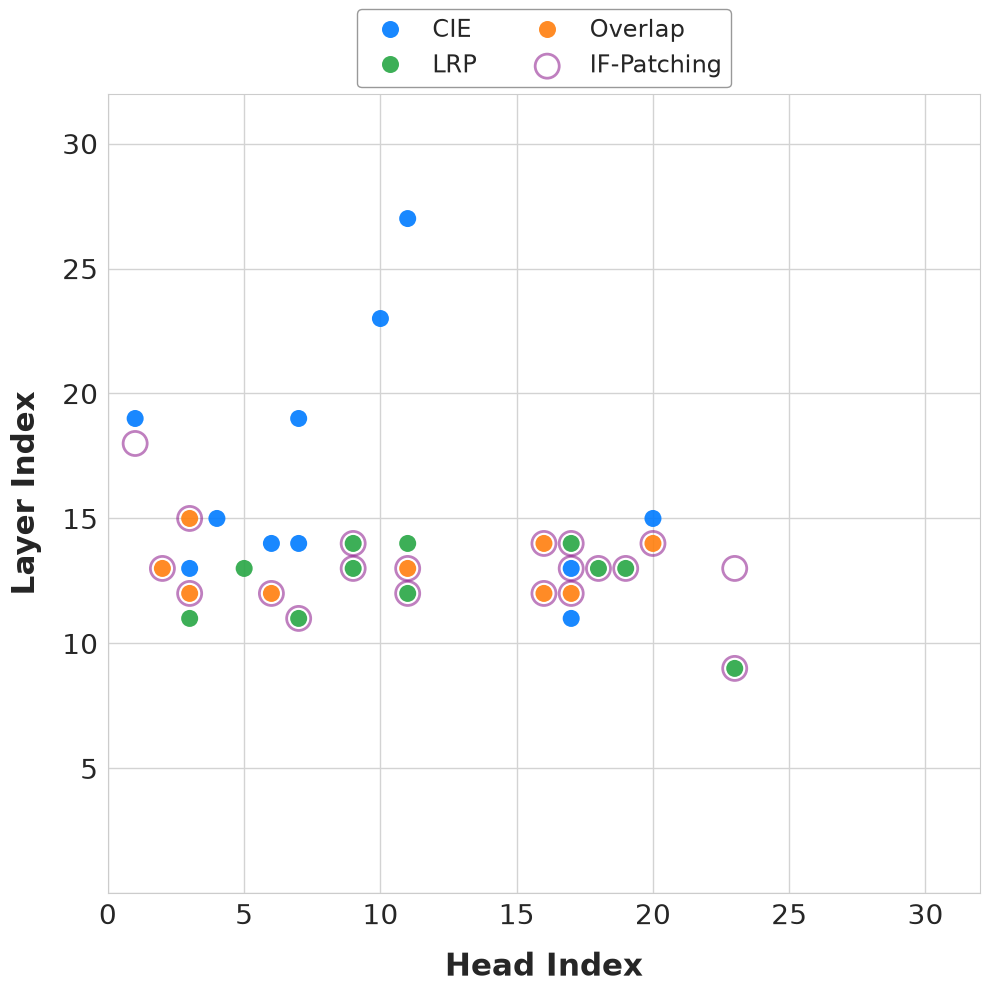

In [39]:
import os
import torch
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Import your native project modules
import utils
import eval as steer_eval

# ─── CONFIGURATION ────────────────────────────────────────────────────────────
STORAGE_ROOT = os.environ.get("FV_STORAGE_ROOT", "storage")
MODEL_NAME = "meta-llama/Llama-3.2-3B-Instruct"
PROMPT_TYPE = "instruction"          
PROMPT_LENGTH = "short"
TOPK_HEADS = 20

# Architecture dimensions for Llama 3.2 3B
MODEL_LAYERS = 32
MODEL_HEADS = 32

# Methods to load & plot (excluding shapley)
BASE_METHOD_1 = "cie"        # Plotted as Blue
BASE_METHOD_2 = "lrp"        # Plotted as Green
OVERLAY_METHOD = "if_patching" # Plotted as a Purple Ring

TASKS = [
    # abstractive
    "antonym", "capitalize", "capitalize_first_letter", "capitalize_last_letter",
    "country-capital", "country-currency", "english-french", "english-german", "english-spanish",
    "landmark-country", "national_parks",
    "next_item", "park-country", "present-past", "prev_item",
    "product-company", "singular-plural", "synonym", "word_length",
    # extractive
    "alphabetically_last_3", "animal_v_object_3", "animal_v_object_5",
    "choose_first_of_3", "choose_first_of_5", "choose_last_of_3", "choose_last_of_5",
    "choose_middle_of_3", "choose_middle_of_5", "color_v_animal_3", "color_v_animal_5",
    "concept_v_object_3", "concept_v_object_5", "conll2003_location", "conll2003_organization", 
    "conll2003_person", "fruit_v_animal_3", "fruit_v_animal_5",
    "object_v_concept_3", "object_v_concept_5", "verb_v_adjective_3", "verb_v_adjective_5",
]

# ─── DATA LOADING VIA UTILS & STEER_EVAL ──────────────────────────────────────
def precompute_global_heads(methods):
    """Loads head scores using project utils and computes top-K heads via steer_eval."""
    print("Precomputing global heads across all tasks...")
    short_model_name = MODEL_NAME[MODEL_NAME.rfind("/") + 1 :] if "/" in MODEL_NAME else MODEL_NAME
    
    global_scores = {m: [] for m in methods}
    
    for task in TASKS:
        save_dir = utils.result_dir(STORAGE_ROOT, short_model_name, task, PROMPT_LENGTH)
        for method in methods:
            scores_path = Path(save_dir) / f"{task}_{PROMPT_TYPE}_{method}_head_scores.pt"
            if scores_path.exists():
                s = torch.load(scores_path, map_location="cpu")
                while s.dim() > 2:
                    s = s.mean(dim=0)
                global_scores[method].append(s)

    global_top_heads = {}
    for method in methods:
        if global_scores[method]:
            avg_score = torch.stack(global_scores[method]).mean(dim=0)
            global_top_heads[method] = steer_eval.select_top_heads(avg_score, TOPK_HEADS)
            print(f"  ✓ Found {len(global_top_heads[method])} global top heads for '{method}'")
        else:
            print(f"  ✗ Warning: No scores found for '{method}' across tasks.")
            global_top_heads[method] = []
            
    return global_top_heads

# ─── PLOTTING FUNCTION ────────────────────────────────────────────────────────
def plot_global_heads_atlas(heads_1, heads_2, heads_overlay, label_1, label_2, label_overlay,
                            depth=MODEL_LAYERS, width=MODEL_HEADS):
    """Plots global heads atlas using exact paper styling."""
    
    # Calculate intersections for base methods
    set1, set2 = set(heads_1), set(heads_2)
    intersection = set1.intersection(set2)
    only_1 = set1 - intersection
    only_2 = set2 - intersection

    data = []
    for l, h in only_1:
        data.append({'Layer': l, 'Head': h, 'Source': label_1})
    for l, h in only_2:
        data.append({'Layer': l, 'Head': h, 'Source': label_2})
    for l, h in intersection:
        data.append({'Layer': l, 'Head': h, 'Source': 'Overlap'})

    df = pd.DataFrame(data)

    plt.figure(figsize=(10, 10))
    sns.set_style("whitegrid")

    palette = {
        label_1: '#007BFF',   # Blue
        label_2: '#28A745',   # Green
        'Overlap': '#ff7f0e'  # Orange
    }

    # Plot base methods (CIE/LRP + Overlap)
    if not df.empty:
        ax = sns.scatterplot(
            data=df,
            x='Head',
            y='Layer',
            hue='Source',
            s=150,
            alpha=0.9,
            palette=palette,
            edgecolor='none',
            linewidth=0,
            zorder=3
        )
    else:
        ax = plt.gca()

    # Overlay IF-Patching as an empty ring (border only)
    if heads_overlay:
        if_layers = [h[0] for h in heads_overlay]
        if_heads = [h[1] for h in heads_overlay]
        ax.scatter(
            if_heads, 
            if_layers, 
            s=300,                    # Larger to cleanly encircle the base dots
            facecolors='none',        # Transparent fill
            edgecolors='#800080',     # Purple border
            linewidths=2,             # Thick border for visibility
            alpha=0.5,
            label=label_overlay,
            zorder=4                  # Render on top so the ring crosses over the solid dots perfectly
        )

    # ─── AXIS ALIGNMENT & STYLING ─────────────────────────────────────────────
    plt.xlim(0, width)
    plt.ylim(0, depth)

    x_ticks = list(range(0, width + 1, 5))
    y_ticks = list(range(0, depth + 1, 5))

    ax.set_xticks(x_ticks)
    ax.set_yticks(y_ticks)

    # Hide '0' on Y-axis to prevent overlap at origin
    y_labels = [str(i) if i != 0 else "" for i in y_ticks]
    ax.set_yticklabels(y_labels, fontsize=20)
    plt.xticks(fontsize=20)

    ax.set_axisbelow(True)
    ax.grid(True, color='lightgrey', linestyle='-', linewidth=1)

    plt.xlabel("Head Index", fontsize=22, labelpad=15, fontweight='bold')
    plt.ylabel("Layer Index", fontsize=22, labelpad=15, fontweight='bold')

    # Legend formatting
    handles, labels = ax.get_legend_handles_labels()
    plt.legend(
        handles=handles,
        labels=labels,
        loc='upper center',
        bbox_to_anchor=(0.5, 1.12),
        ncol=2,
        fontsize=17,
        frameon=True,
        edgecolor='gray'
    )

    plt.tight_layout()

    # Save as 300 DPI PDF
    output_filename = "global_heads_atlas.pdf"
    plt.savefig(output_filename, format='pdf', dpi=300, bbox_inches='tight')
    print(f"\nPlot successfully saved as {output_filename} at 300 DPI")

    plt.show()

# ─── MAIN EXECUTION ───────────────────────────────────────────────────────────
if __name__ == "__main__":
    methods_to_load = [BASE_METHOD_1, BASE_METHOD_2, OVERLAY_METHOD]
    
    global_heads = precompute_global_heads(methods_to_load)
    
    plot_global_heads_atlas(
        heads_1=global_heads.get(BASE_METHOD_1, []),
        heads_2=global_heads.get(BASE_METHOD_2, []),
        heads_overlay=global_heads.get(OVERLAY_METHOD, []),
        label_1=BASE_METHOD_1.upper(),
        label_2=BASE_METHOD_2.upper(),
        label_overlay="IF-Patching" if OVERLAY_METHOD == "if_patching" else OVERLAY_METHOD.upper()
    )

In [2]:
df_final

,Model,Method,Top-1 Accuracy
11,Llama-3.2-3B,LRP + dist. FV,0.813410
7,Llama-3.2-3B,CIE + dist. FV,0.710893
9,Llama-3.2-3B,IF + dist. FV,0.783106
10,Llama-3.2-3B,LRP + FV,0.755670
6,Llama-3.2-3B,CIE + FV,0.573317
8,Llama-3.2-3B,IF + FV,0.714723
5,Llama-3.1-8B,LRP + dist. FV,0.755555
1,Llama-3.1-8B,CIE + dist. FV,0.616629
3,Llama-3.1-8B,IF + dist. FV,0.720884
4,Llama-3.1-8B,LRP + FV,0.578677


In [5]:
import pandas as pd

def calculate_average_gains(df_final):
    """
    Calculates:
    1. Average gain of dist. FV over FV (excluding IF)
    2. Average gain of LRP over AIE/CIE (excluding IF)
    3. Difference between LRP and IF Patching
    """
    if df_final is None or df_final.empty:
        print("Dataframe is empty. Cannot calculate gains.")
        return
        
    # 1. Create a working copy and split Method into Base Method and Steering
    df = df_final.copy()
    df['Extraction'] = df['Method'].apply(lambda x: x.split(' + ')[0].strip())
    df['Steering'] = df['Method'].apply(lambda x: x.split(' + ')[1].strip())
    
    # 2. Create subsets for calculations
    df_no_if = df[df['Extraction'] != 'IF']
    df_lrp_if = df[df['Extraction'].isin(['LRP', 'IF'])]
    
    # --- CALCULATION 1: dist. FV vs FV (Excluding IF) ---
    pivot_steering = df_no_if.pivot_table(
        index=['Model', 'Extraction'], 
        columns='Steering', 
        values='Top-1 Accuracy'
    )
    pivot_steering['Gain (dist over FV)'] = pivot_steering['dist. FV'] - pivot_steering['FV']
    
    # --- CALCULATION 2: LRP vs AIE(CIE) (Excluding IF) ---
    pivot_extraction_cie = df_no_if.pivot_table(
        index=['Model', 'Steering'], 
        columns='Extraction', 
        values='Top-1 Accuracy'
    )
    pivot_extraction_cie['Gain (LRP over CIE)'] = pivot_extraction_cie['LRP'] - pivot_extraction_cie['CIE']
    
    # --- CALCULATION 3: LRP vs IF-Patching ---
    pivot_extraction_if = df_lrp_if.pivot_table(
        index=['Model', 'Steering'], 
        columns='Extraction', 
        values='Top-1 Accuracy'
    )
    pivot_extraction_if['Gain (LRP over IF)'] = pivot_extraction_if['LRP'] - pivot_extraction_if['IF']

    # Calculate overall averages
    avg_dist_gain = pivot_steering['Gain (dist over FV)'].mean()
    avg_lrp_gain = pivot_extraction_cie['Gain (LRP over CIE)'].mean()
    avg_lrp_over_if = pivot_extraction_if['Gain (LRP over IF)'].mean()
    
    # --- PRINTING RESULTS ---
    print("\n" + "="*55)
    print("1. GAIN OF dist. FV over FV (Excluding IF)")
    print("="*55)
    print(pivot_steering[['FV', 'dist. FV', 'Gain (dist over FV)']].round(4).to_string())
    print(f"\n=> AVERAGE 'dist. FV' GAIN: {avg_dist_gain:+.4f} ({avg_dist_gain * 100:+.2f} percentage points)")
    
    print("\n" + "="*55)
    print("2. GAIN OF LRP over AIE/CIE (Excluding IF)")
    print("="*55)
    print(pivot_extraction_cie[['CIE', 'LRP', 'Gain (LRP over CIE)']].round(4).to_string())
    print(f"\n=> AVERAGE 'LRP' GAIN (over CIE): {avg_lrp_gain:+.4f} ({avg_lrp_gain * 100:+.2f} percentage points)")

    print("\n" + "="*55)
    print("3. DIFFERENCE BETWEEN LRP AND IF-PATCHING")
    print("="*55)
    print(pivot_extraction_if[['IF', 'LRP', 'Gain (LRP over IF)']].round(4).to_string())
    print(f"\n=> AVERAGE 'LRP' GAIN (over IF): {avg_lrp_over_if:+.4f} ({avg_lrp_over_if * 100:+.2f} percentage points)")
    print("="*55 + "\n")
    
    return {
        "avg_dist_gain": avg_dist_gain,
        "avg_lrp_gain_over_cie": avg_lrp_gain,
        "avg_lrp_gain_over_if": avg_lrp_over_if,
        "detailed_steering_df": pivot_steering,
        "detailed_extraction_cie_df": pivot_extraction_cie,
        "detailed_extraction_if_df": pivot_extraction_if
    }

# --- Execute it by passing in your dataframe ---
gains = calculate_average_gains(df_final)


1. GAIN OF dist. FV over FV (Excluding IF)
Steering                     FV  dist. FV  Gain (dist over FV)
Model        Extraction                                       
Llama-3.2-3B CIE         0.5733    0.7109               0.1376
             LRP         0.7557    0.8134               0.0577
Llama-3.1-8B CIE         0.4707    0.6166               0.1459
             LRP         0.5787    0.7556               0.1769
Qwen3-4B     CIE         0.4517    0.5267               0.0750
             LRP         0.5185    0.6024               0.0839

=> AVERAGE 'dist. FV' GAIN: +0.1128 (+11.28 percentage points)

2. GAIN OF LRP over AIE/CIE (Excluding IF)
Extraction                CIE     LRP  Gain (LRP over CIE)
Model        Steering                                     
Llama-3.2-3B FV        0.5733  0.7557               0.1824
             dist. FV  0.7109  0.8134               0.1025
Llama-3.1-8B FV        0.4707  0.5787               0.1080
             dist. FV  0.6166  0.7556            